# H1b exploratory, Stage 1: nominal vs real, integration, long-run assessment

**Exploratory (ADR 0008 §9).** Nothing here tests the frozen H1b claim (ADR 0008 §2), which is
NOT ASSESSABLE. The 5 % level used below is a descriptive reference
it does not inherit H1b's
unused α = 0.025 (ADR 0008 §7.1). A fitted long-run combination is at most a *model-implied
benchmark*, never a "fair value" (§7.2).

Order (ADR 0008 §9.0): §9.1 descriptives → §9.2 integration (pre-period) → §9.3 applicability,
decided before any levels estimate → §9.4 assessment (pre-period only). Window data enter only
the §9.1 descriptives. Stage 2 (post-2022 deviations) is not run here.

In [1]:
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.diagnostic import het_arch
from statsmodels.stats.stattools import jarque_bera

from kagura import longrun as lr
from kagura.explore import ERAS, EVENTS, save

pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)
df = lr.load_monthly()  # verifies all 10 frozen checksums first
pre = df.loc[lr.PRE_START : lr.PRE_END]
print(
    df.shape,
    "| pre-period rows:",
    len(pre),
    "| missing in window:",
    df.loc["2022-01":].isna().sum().to_dict(),
)

(547, 7) | pre-period rows: 492 | missing in window: {'s': 0, 'd2': 0, 'd10': 0, 'x': 1, 'q': 1, 'r': 1, 'x_tax': 1}


## §9.1 Nominal vs real USD/JPY (descriptive, no models)

`s` = 100 ln USD/JPY, `x` = 100 ln(CPI_JP/CPI_US), `q = s − x` (CPI-based real rate
up =
real yen depreciation), `d2`/`d10` = US−Japan 2Y/10Y (pp), `r` = d2 minus the realised
12-month inflation gap (proxy, no expectations data).

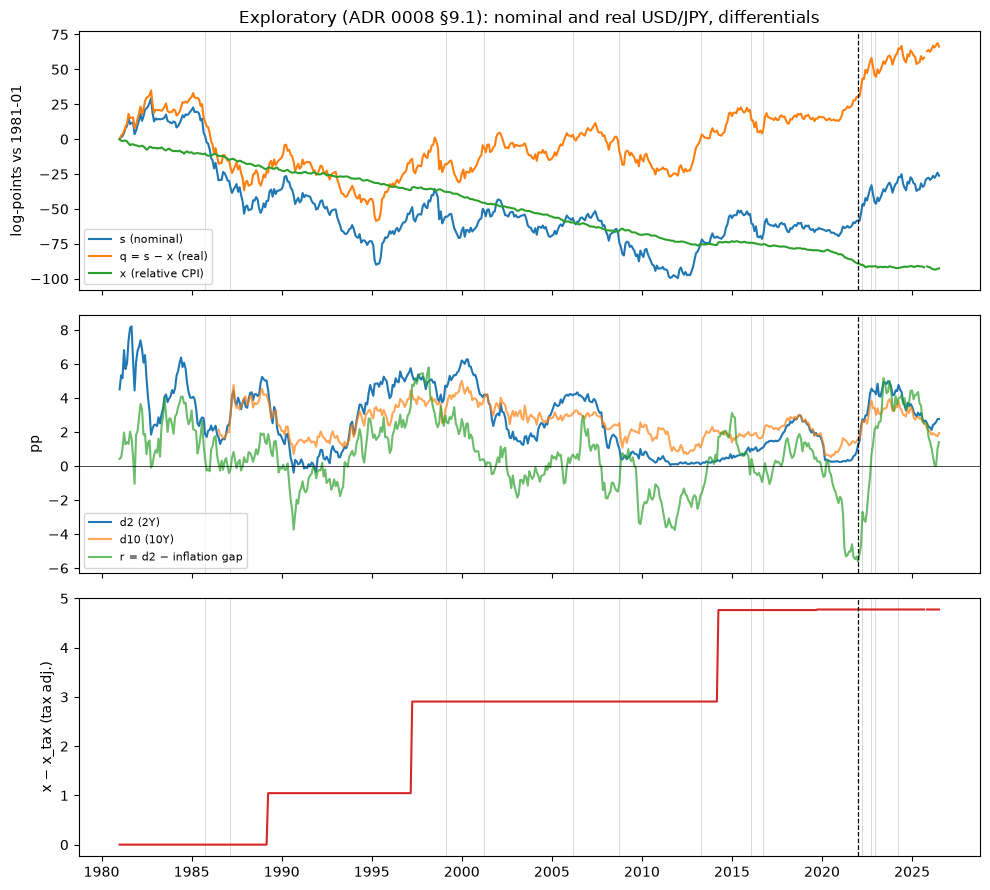

In [2]:
def markers(ax):
    for date in EVENTS:
        ax.axvline(pd.Timestamp(date), color="0.8", lw=0.5, zorder=0)
    ax.axvline(pd.Timestamp("2022-01-01"), color="k", lw=0.9, ls="--")


t = df.index.to_timestamp()
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
ax = axes[0]
ax.plot(t, df.s - df.s.iloc[0], label="s (nominal)")
ax.plot(t, df.q - df.q.iloc[0], label="q = s − x (real)")
ax.plot(t, df.x - df.x.iloc[0], label="x (relative CPI)")
ax.set_ylabel("log-points vs 1981-01")
ax.legend(fontsize=8)
markers(ax)
ax = axes[1]
ax.plot(t, df.d2, label="d2 (2Y)")
ax.plot(t, df.d10, label="d10 (10Y)", alpha=0.7)
ax.plot(t, df.r, label="r = d2 − inflation gap", alpha=0.7)
ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("pp")
ax.legend(fontsize=8)
markers(ax)
ax = axes[2]
ax.plot(t, df.x - df.x_tax, color="C3")
ax.set_ylabel("x − x_tax (tax adj.)")
markers(ax)
axes[0].set_title("Exploratory (ADR 0008 §9.1): nominal and real USD/JPY, differentials")
fig.tight_layout()
save(fig, "h1b_01_nominal_real")

In [3]:
# Arithmetic split of the window change: Δs = Δq + Δx (ends 2022-01 and 2026-07; no estimation)
a, b = df.loc["2021-12"], df.loc["2026-07"]
split = pd.Series(
    {
        "Δs": b.s - a.s,
        "Δq (real)": b.q - a.q,
        "Δx (relative CPI)": b.x - a.x,
        "Δd2 (pp)": b.d2 - a.d2,
        "Δr (pp)": b.r - a.r,
    }
)
print("2021-12 → 2026-07, log-points (×100):")
print(split.round(2).to_string())
print(f"\nUSD/JPY {math.exp(a.s / 100):.1f} → {math.exp(b.s / 100):.1f}")

# Same split over each earlier 55-month span, for scale (descriptive)
spans = pd.DataFrame({"Δs": df.s.diff(55), "Δq": df.q.diff(55), "Δx": df.x.diff(55)}).loc[
    "1985-08":"2021-12"
]
print("\nPre-period 55-month changes, distribution (log-points):")
print(spans.describe(percentiles=[0.05, 0.5, 0.95]).round(1).to_string())

2021-12 → 2026-07, log-points (×100):
Δs                   32.35
Δq (real)            36.14
Δx (relative CPI)    -3.79
Δd2 (pp)              1.95
Δr (pp)               6.72

USD/JPY 115.2 → 159.2

Pre-period 55-month changes, distribution (log-points):
          Δs     Δq     Δx
count  437.0  437.0  437.0
mean    -9.8   -0.5   -9.3
std     24.7   23.7    3.3
min    -68.6  -59.0  -14.6
5%     -55.9  -45.1  -14.0
50%     -7.1    3.8   -9.7
95%     32.6   34.8   -2.1
max     43.2   47.4   -0.8


In [4]:
# ADR 0004 eras (fixed in advance): means and sds
rows = {}
for era, (lo, hi) in ERAS.items():
    sub = df.loc[pd.Period(lo[:7], "M") : pd.Period(min(hi, "2026-07-31")[:7], "M")]
    rows[era] = {
        "months": len(sub),
        "s mean": sub.s.mean(),
        "q mean": sub.q.mean(),
        "q sd": sub.q.std(),
        "d2 mean": sub.d2.mean(),
        "r mean": sub.r.mean(),
        "USDJPY mean": np.exp(sub.s / 100).mean(),
    }
print(pd.DataFrame(rows).T.round(2).to_string())

           months  s mean  q mean   q sd  d2 mean  r mean  USDJPY mean
1981–1989   108.0  524.24  544.65  21.79     3.97    1.35       195.58
1990–1998   108.0  477.17  515.96  13.50     2.85    1.16       119.32
1999–2012   168.0  464.92  531.84  10.18     2.50   -0.23       105.64
2013–2021   108.0  469.12  555.88   7.07     1.06   -0.17       109.20
2022–        55.0  497.78  598.30   8.59     3.51    2.01       145.60


## §9.2 Integration diagnostics (pre-period 1981-01…2021-12)

ADF (AIC lags ≤ 12, constant
plus trend for x, x_tax and q in levels) and KPSS, on levels and
first differences. Δx and Δx_tax are filtered for centred calendar-month and tax-month effects.
Class rule (ADR 0008 §9.2): **I(2) risk** if the difference is not I(0)
else **I(0)** if level
ADF rejects and KPSS does not
**I(1)** if level ADF does not reject and KPSS rejects
else
**ambiguous**. 5 % is a descriptive reference. Both tests have low power near a unit root, and
breaks can mimic unit roots (ADR 0004).

In [5]:
SPECS = {  # name: (trend in level test, seasonal filter on difference)
    "s": (False, False),
    "q": (True, True),
    "x": (True, True),
    "x_tax": (True, True),
    "d2": (False, False),
    "d10": (False, False),
    "r": (False, False),
}


def table(frame):
    out = [lr.classify(n, frame[n], trend=tr, seasonal=se) for n, (tr, se) in SPECS.items()]
    return pd.DataFrame([o.__dict__ for o in out]).set_index("name")


integ = table(pre)
print("Pre-period 1981-01…2021-12 (d10 from 1986-07):")
print(integ.round(3).to_string())

Pre-period 1981-01…2021-12 (d10 from 1986-07):
       adf_level_p  kpss_level_p  adf_diff_p  kpss_diff_p  adf_lags  max_root_diff klass
name                                                                                    
s            0.276          0.01         0.0          0.1         2          0.881  I(1)
q            0.643          0.01         0.0          0.1         2          0.878  I(1)
x            0.334          0.01         0.0          0.1        12          0.881  I(1)
x_tax        0.420          0.01         0.0          0.1        12          0.881  I(1)
d2           0.069          0.01         0.0          0.1         3          0.858  I(1)
d10          0.110          0.01         0.0          0.1         2          0.838  I(1)
r            0.301          0.01         0.0          0.1        12          0.917  I(1)


In [6]:
sens_1990 = table(df.loc["1990-01":"2021-12"])["klass"].rename("1990–2021")
sens_full = table(df)["klass"].rename("1981–2026-07 (includes window; never feeds §9.3)")
print(
    pd.concat(
        [integ["klass"].rename("1981–2021 (primary)"), sens_1990, sens_full], axis=1
    ).to_string()
)

      1981–2021 (primary)  1990–2021 1981–2026-07 (includes window; never feeds §9.3)
name                                                                                 
s                    I(1)       I(1)                                             I(1)
q                    I(1)  ambiguous                                             I(1)
x                    I(1)       I(1)                                             I(1)
x_tax                I(1)       I(1)                                             I(1)
d2                   I(1)  ambiguous                                        ambiguous
d10                  I(1)       I(1)                                        ambiguous
r                    I(1)       I(1)                                             I(0)


## §9.3 Estimator applicability (decided from §9.2 alone, before any levels estimate)

Rules (ADR 0008 §9.3, with the final I(2) correction): every series in a specification is
assessed on its own
any series with I(2) risk excludes every specification it enters
ARDL
bounds need all variables I(0)/I(1) (ambiguous between I(0) and I(1) is admissible)
FM-OLS and
D-OLS need I(1) regressors, so an I(0) differential is not used as one (γ then comes from the
ARDL only)
a dependent variable classified I(0) ends that specification's levels question.

In [7]:
SPEC_VARS = {  # (dependent, [regressors], sample start)
    "(a) s on x, d2": ("s", ["x", "d2"], "1981-01"),
    "(b) q on d2 (PPP imposed)": ("q", ["d2"], "1981-01"),
    "(c) s on x, d10": ("s", ["x", "d10"], "1986-07"),
    "(d) s on x_tax, d2": ("s", ["x_tax", "d2"], "1981-01"),
}
k_of = integ["klass"].to_dict()


def applicability(dep, regs):
    classes = {v: k_of[v] for v in [dep, *regs]}
    i2 = [v for v, c in classes.items() if c == "I(2) risk"]
    if i2:
        return dict(ardl=False, fm_dols="none", reason=f"I(2) risk: {', '.join(i2)}")
    if classes[dep] == "I(0)":
        return dict(ardl=False, fm_dols="none", reason=f"dependent {dep} is I(0)")
    i1_regs = [v for v in regs if classes[v] == "I(1)"]
    amb = [v for v in regs if classes[v] == "ambiguous"]
    if not i1_regs and not amb:
        fm = "none"
    elif amb:
        fm = (
            "both treatments: "
            + "+".join(i1_regs + amb)
            + " as I(1), and "
            + ("+".join(i1_regs) or "none")
        )
    else:
        fm = "+".join(i1_regs)
    return dict(
        ardl=True, fm_dols=fm, reason="all I(0)/I(1)/ambiguous; FM/D-OLS on I(1) regressors only"
    )


appl = pd.DataFrame(
    {
        name: {**applicability(dep, regs), "classes": {v: k_of[v] for v in [dep, *regs]}}
        for name, (dep, regs, _) in SPEC_VARS.items()
    }
).T
print(appl.to_string())

                           ardl   fm_dols                                                     reason                                       classes
(a) s on x, d2             True      x+d2  all I(0)/I(1)/ambiguous; FM/D-OLS on I(1) regressors only      {'s': 'I(1)', 'x': 'I(1)', 'd2': 'I(1)'}
(b) q on d2 (PPP imposed)  True        d2  all I(0)/I(1)/ambiguous; FM/D-OLS on I(1) regressors only                   {'q': 'I(1)', 'd2': 'I(1)'}
(c) s on x, d10            True     x+d10  all I(0)/I(1)/ambiguous; FM/D-OLS on I(1) regressors only     {'s': 'I(1)', 'x': 'I(1)', 'd10': 'I(1)'}
(d) s on x_tax, d2         True  x_tax+d2  all I(0)/I(1)/ambiguous; FM/D-OLS on I(1) regressors only  {'s': 'I(1)', 'x_tax': 'I(1)', 'd2': 'I(1)'}


## §9.4 Long-run model assessment (pre-period only)

Bounds statistics are compared with the PSS (2001) 5 % bounds and with simulated 95 %
full-procedure quantiles (BG-filtered AIC over p, q ≤ 12
independent driftless random walks;
synthetic data, fixed seeds). Layers A–D are reported separately
the classification at the end
is a written judgment, not a test.

In [8]:
SIM_REPS = 2000
sim_q = {}
for name, (_dep, regs, start) in SPEC_VARS.items():
    if not appl.loc[name, "ardl"]:
        continue
    n = len(pre.loc[start:])
    key = (n, len(regs))
    if key not in sim_q:
        sim_q[key] = lr.simulate_bounds_quantiles(
            n, len(regs), SIM_REPS, seed=20261024 + n + len(regs)
        )
print("Simulated 95 % full-procedure quantiles (F upper, t lower), R =", SIM_REPS, ":", sim_q)

Simulated 95 % full-procedure quantiles (F upper, t lower), R = 2000 : {(492, 2): (4.93370771379685, -3.5389775970971327), (492, 1): (5.818833642484107, -3.2512301595944995), (426, 2): (4.993439820082975, -3.63006511206541)}


In [9]:
fits, rows = {}, {}
for name, (dep, regs, start) in SPEC_VARS.items():
    if not appl.loc[name, "ardl"]:
        rows[name] = {"applicable": False, "reason": appl.loc[name, "reason"]}
        continue
    sub = pre.loc[start:]
    y, X = sub[dep].to_numpy(float), sub[regs].to_numpy(float)
    f = lr.select_ardl(y, X)
    hl = lr.half_life(lr.ar_polynomial(f))
    boot = lr.bootstrap_half_life(y, X, f, draws=999, block=24, seed=20261024)
    lo, hi = np.quantile(boot, [0.05, 0.95])
    Fi0, Fi1, ti0, ti1 = lr.PSS_5PCT[len(regs)]
    Fs, ts = sim_q[(len(sub), len(regs))]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        arch_p = het_arch(f.resid, nlags=12)[1]
    jb_p = jarque_bera(f.resid)[1]
    fits[name] = (f, y, X, sub)
    row = {
        "applicable": True,
        "T used": f.nobs,
        "p": f.p,
        "q": f.q,
        "F": f.f_stat,
        "F PSS I(0)/I(1)": f"{Fi0}/{Fi1}",
        "F sim95": Fs,
        "t": f.t,
        "t PSS I(0)/I(1)": f"{ti0}/{ti1}",
        "t sim5": ts,
        "phi": f.phi,
        "BG12 p": f.bg_p,
        "BG passed": f.bg_passed,
        "ARCH12 p": arch_p,
        "JB p": jb_p,
        "half-life (m)": hl,
        "HL 90% lo": lo,
        "HL 90% hi": hi,
        "HL boot share inf": np.mean(np.isinf(boot)),
    }
    for j, v in enumerate(regs):
        row[f"LR {v}"] = f.long_run[j]
        row[f"LR {v} se HAC"] = f.lr_se_hac[j]
        row[f"LR {v} se OLS"] = f.lr_se_ols[j]
    rows[name] = row
ardl_tab = pd.DataFrame(rows).T
print(ardl_tab.T.to_string())

                  (a) s on x, d2 (b) q on d2 (PPP imposed) (c) s on x, d10 (d) s on x_tax, d2
applicable                  True                      True            True               True
T used                       479                       479             413                479
p                             12                         3              12                 12
q                              1                         2               1                  1
F                           4.08                     1.877           3.513              3.974
F PSS I(0)/I(1)        3.79/4.85                 4.94/5.73       3.79/4.85          3.79/4.85
F sim95                    4.934                     5.819           4.993              4.934
t                         -1.868                     -0.98          -2.978             -1.876
t PSS I(0)/I(1)      -2.86/-3.53               -2.86/-3.22     -2.86/-3.53        -2.86/-3.53
t sim5                    -3.539                    -3.251  

In [10]:
# Long-run forcing (§9.3): loadings of Δx and Δd on the lagged ARDL equilibrium error
force = {}
for name, (f, y, X, _sub) in fits.items():
    _dep, regs, _ = SPEC_VARS[name]
    ect = y - X @ f.long_run
    L = max(f.p, f.q)
    D = np.diff(np.column_stack([y, X]), axis=0)
    rows_ = {}
    for j, v in enumerate(regs):
        dz = D[L:, 1 + j]
        ctrl = np.column_stack([D[L - i : len(D) - i] for i in range(1, L + 1)])
        b, tval = lr.loading(dz, ect[L : len(ect) - 1], ctrl)
        rows_[f"Δ{v} loading"] = b
        rows_[f"Δ{v} HAC t"] = tval
    force[name] = rows_
print(pd.DataFrame(force).T.round(3).to_string())

                           Δx loading  Δx HAC t  Δd2 loading  Δd2 HAC t  Δd10 loading  Δd10 HAC t  Δx_tax loading  Δx_tax HAC t
(a) s on x, d2                  0.001     1.288          0.0      0.385           NaN         NaN             NaN           NaN
(b) q on d2 (PPP imposed)         NaN       NaN          0.0      0.965           NaN         NaN             NaN           NaN
(c) s on x, d10                 0.000     0.121          NaN        NaN        -0.001       -0.65             NaN           NaN
(d) s on x_tax, d2                NaN       NaN          0.0      0.299           NaN         NaN           0.001         1.607


In [11]:
# FM-OLS and D-OLS where §9.3 allows (I(1) regressors only); approximate intervals (x drifts)
cmp = {}
for name, (dep, regs, start) in SPEC_VARS.items():
    if not appl.loc[name, "ardl"]:
        continue
    sub = pre.loc[start:]
    y = sub[dep].to_numpy(float)
    i1 = [v for v in regs if k_of[v] == "I(1)"]
    amb = [v for v in regs if k_of[v] == "ambiguous"]
    variants = {}
    if i1:
        variants["I(1) block: " + "+".join(i1)] = (i1, [v for v in regs if v not in i1])
    if amb:
        variants["ambiguous as I(1): " + "+".join(i1 + amb)] = (i1 + amb, [])
    for label, (reg1, stat) in variants.items():
        X1 = sub[reg1].to_numpy(float)
        fm = lr.fmols(y, X1)
        do = lr.dols(y, X1)
        for est, fit in (("FM-OLS", fm), ("D-OLS", do)):
            for j, v in enumerate(reg1):
                cmp[(name, label, est, v)] = {
                    "coef": fit.coef[1 + j],
                    "se": fit.se[1 + j],
                    "bw/leads": fit.bandwidth if est == "FM-OLS" else fit.extra,
                }
        if stat:  # sensitivity: D-OLS with the I(0) differential as a stationary level regressor
            ds = lr.dols(y, X1, sub[stat].to_numpy(float))
            for j, v in enumerate(reg1 + stat):
                cmp[(name, label, "D-OLS + stationary " + "+".join(stat), v)] = {
                    "coef": ds.coef[1 + j],
                    "se": ds.se[1 + j],
                    "bw/leads": ds.extra,
                }
    f = fits[name][0]
    for j, v in enumerate(regs):
        cmp[(name, "ARDL", "ARDL", v)] = {
            "coef": f.long_run[j],
            "se": f.lr_se_hac[j],
            "bw/leads": f"p={f.p},q={f.q}",
        }
cmp_tab = pd.DataFrame(cmp).T
print(cmp_tab.to_string())

                                                               coef      se  bw/leads
(a) s on x, d2            I(1) block: x+d2     FM-OLS x       0.821   0.235   174.558
                                                      d2      -0.06    3.08   174.558
                                               D-OLS  x       0.805   0.259       0.0
                                                      d2      0.655   3.389       0.0
                          ARDL                 ARDL   x      -0.301   0.726  p=12,q=1
                                                      d2     15.999  11.135  p=12,q=1
(b) q on d2 (PPP imposed) I(1) block: d2       FM-OLS d2     -2.178   2.996   186.556
                                               D-OLS  d2     -0.937   3.107       2.0
                          ARDL                 ARDL   d2     16.194  21.074   p=3,q=2
(c) s on x, d10           I(1) block: x+d10    FM-OLS x        0.43   0.138    88.145
                                                      

### Layer D: stability (ARDL at the full-sample orders)

ADR 0004 eras within the pre-period, 120-month rolling windows and recursive (expanding from
1981, ≥ 120 months) estimates of the long-run coefficients and φ.

In [12]:
PRE_ERAS = {k: v for k, v in ERAS.items() if v[1] <= "2021-12-31"}
stab, paths = {}, {}
for name, (f, y, X, sub) in fits.items():
    _dep, regs, _ = SPEC_VARS[name]
    for era, (lo, hi) in PRE_ERAS.items():
        m = (sub.index >= pd.Period(lo[:7], "M")) & (sub.index <= pd.Period(hi[:7], "M"))
        if m.sum() < 60:
            continue
        g = lr.fit_ardl(y[m], X[m], f.p, f.q)
        stab[(name, era)] = {
            "T": g.nobs,
            "phi": g.phi,
            "t": g.t,
            **{f"LR {v}": g.long_run[j] for j, v in enumerate(regs)},
            **{f"LR {v} se": g.lr_se_hac[j] for j, v in enumerate(regs)},
        }
    roll, rec = [], []
    for end in range(120, len(y) + 1, 3):
        g = lr.fit_ardl(y[end - 120 : end], X[end - 120 : end], f.p, f.q)
        h = lr.fit_ardl(y[:end], X[:end], f.p, f.q)
        roll.append([sub.index[end - 1].to_timestamp(), g.phi, *g.long_run])
        rec.append([sub.index[end - 1].to_timestamp(), h.phi, *h.long_run])
    paths[name] = (
        pd.DataFrame(roll, columns=["date", "phi", *regs]).set_index("date"),
        pd.DataFrame(rec, columns=["date", "phi", *regs]).set_index("date"),
    )
stab_tab = pd.DataFrame(stab).T
print(stab_tab.round(3).to_string())

                                         T    phi      t    LR x   LR d2  LR x se  LR d2 se  LR d10  LR d10 se  LR x_tax  LR x_tax se
(a) s on x, d2            1981–1989   95.0 -0.057 -1.288   3.570  14.964    1.401    13.581     NaN        NaN       NaN          NaN
                          1990–1998   95.0  0.027  0.516  -2.798 -26.226   10.990    29.438     NaN        NaN       NaN          NaN
                          1999–2012  155.0 -0.064 -2.784   0.649   7.094    0.444     2.966     NaN        NaN       NaN          NaN
                          2013–2021   95.0 -0.191 -3.204   0.217   0.171    0.278     1.067     NaN        NaN       NaN          NaN
(b) q on d2 (PPP imposed) 1981–1989   95.0 -0.024 -1.491     NaN  41.046      NaN    24.596     NaN        NaN       NaN          NaN
                          1990–1998   95.0 -0.016 -0.522     NaN  16.914      NaN    41.266     NaN        NaN       NaN          NaN
                          1999–2012  155.0 -0.059 -2.577     N

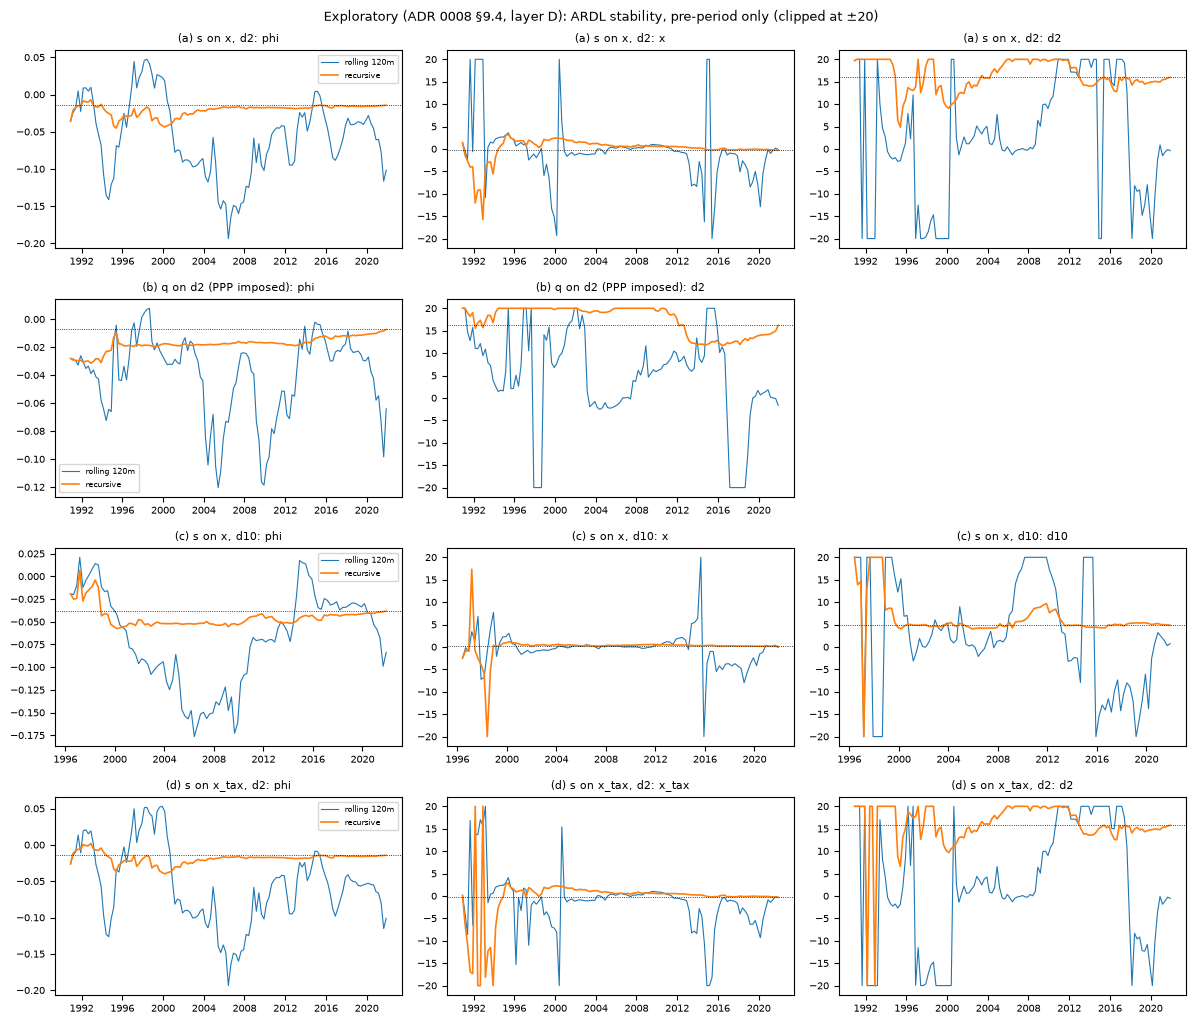

In [13]:
if paths:
    names = list(paths)
    ncoef = max(len(SPEC_VARS[n][1]) for n in names) + 1
    fig, axes = plt.subplots(
        len(names), ncoef, figsize=(4 * ncoef, 2.6 * len(names)), squeeze=False
    )
    for i, name in enumerate(names):
        roll, rec = paths[name]
        f = fits[name][0]
        for j, col in enumerate(roll.columns):
            ax = axes[i, j]
            ax.plot(roll.index, roll[col].clip(-20, 20), lw=0.8, label="rolling 120m")
            ax.plot(rec.index, rec[col].clip(-20, 20), lw=1.2, label="recursive")
            full = f.phi if col == "phi" else f.long_run[SPEC_VARS[name][1].index(col)]
            ax.axhline(full, color="k", lw=0.6, ls=":")
            ax.set_title(f"{name}: {col}", fontsize=8)
            ax.tick_params(labelsize=7)
        axes[i, 0].legend(fontsize=6)
        for j in range(len(roll.columns), ncoef):
            axes[i, j].set_visible(False)
    fig.suptitle(
        "Exploratory (ADR 0008 §9.4, layer D): ARDL stability, pre-period only (clipped at ±20)",
        fontsize=9,
    )
    fig.tight_layout()
    save(fig, "h1b_02_stability")

### Screening benchmarks by layer (descriptive flags, ADR 0008 §9.4)

In [14]:
flags = {}
for name, (_dep, regs, _start) in SPEC_VARS.items():
    if not appl.loc[name, "ardl"]:
        flags[name] = {"A applicable": False}
        continue
    r = ardl_tab.loc[name]
    f = fits[name][0]
    Fi0, Fi1, ti0, ti1 = lr.PSS_5PCT[len(regs)]
    Fs, ts = sim_q[(len(fits[name][3]), len(regs))]
    fl = {
        "A applicable": True,
        "B F > PSS I(1)": r["F"] > Fi1,
        "B F > sim95": r["F"] > Fs,
        "B F < PSS I(0)": r["F"] < Fi0,
        "B t < PSS I(1)": r["t"] < ti1,
        "B t < sim5": r["t"] < ts,
        "B t > PSS I(0)": r["t"] > ti0,
        "B BG clean": bool(r["BG passed"]),
        "B HL 90% hi finite & < 120m": np.isfinite(r["HL 90% hi"]) and r["HL 90% hi"] < 120,
    }
    if "x" in regs[0]:
        th, se = f.long_run[0], f.lr_se_hac[0]
        fl["C theta in (0,2)"] = 0 < th < 2
        fl["C theta CI overlaps (0,2)"] = (th + 1.96 * se > 0) and (th - 1.96 * se < 2)
    g = f.long_run[-1]
    fl["C gamma > 0 (ARDL)"] = g > 0
    est_signs = cmp_tab.loc[[i for i in cmp_tab.index if i[0] == name and i[3] == regs[-1]], "coef"]
    fl["C gamma sign agrees across estimators"] = bool(
        (np.sign(est_signs.astype(float)) == np.sign(g)).all()
    )
    era_rows = stab_tab.loc[[i for i in stab_tab.index if i[0] == name]]
    for j, v in enumerate(regs):
        full, fse = f.long_run[j], f.lr_se_hac[j]
        er, es = era_rows[f"LR {v}"].astype(float), era_rows[f"LR {v} se"].astype(float)
        fl[f"D {v} sign same in ≥3/4 eras"] = int((np.sign(er) == np.sign(full)).sum()) >= 3
        fl[f"D {v} era CIs overlap full CI"] = bool(
            ((er + 1.96 * es >= full - 1.96 * fse) & (er - 1.96 * es <= full + 1.96 * fse)).all()
        )
    flags[name] = fl
flag_tab = pd.DataFrame(flags)
print(flag_tab.to_string())

                                      (a) s on x, d2 (b) q on d2 (PPP imposed) (c) s on x, d10 (d) s on x_tax, d2
A applicable                                    True                      True            True               True
B F > PSS I(1)                                 False                     False           False              False
B F > sim95                                    False                     False           False              False
B F < PSS I(0)                                 False                      True            True              False
B t < PSS I(1)                                 False                     False           False              False
B t < sim5                                     False                     False           False              False
B t > PSS I(0)                                  True                      True           False               True
B BG clean                                      True                      True          

### Classification (written judgment after reading the output above; not a test)

**Caveat on the half-life intervals.** The bootstrap rebuilds y from the *fitted*, stable
ARDL, so it cannot represent the unit-root case
near a unit root such intervals are known to
be too narrow. A finite interval therefore carries no weight against layer B.

| Specification | Class | Reasons |
|---|---|---|
| (a) s on x, d2 | **Not defensible** | B: t = −1.87 does not pass even the PSS I(0) bound (−2.86), so there is no error-correction support
F = 4.08 is in the inconclusive band and below the simulated 95 % quantile (4.93)
φ = −0.014. C: θ = −0.30 (wrong sign for PPP)
γ = 16.0 (HAC se 11.1). Estimators disagree: FM-OLS/D-OLS give θ ≈ 0.8 and γ ≈ 0 (±3). D: φ > 0 in 1990–98
era γ 15.0, −26.2, 7.1, 0.2. |
| (b) q on d2 (PPP imposed) | **Not defensible** | B: F = 1.88 and t = −0.98 are both inside the I(0) bounds
half-life interval reaches 183 months. FM-OLS/D-OLS γ negative, ARDL positive. q's own classification (I(1)) was checked first (§9.3). |
| (c) s on x, d10 (1986–2021) | **Not defensible** (closest to fragile) | B: F = 3.51 is below the I(0) bound (3.79)
t = −2.98 is in the inconclusive band. C: θ = 0.12 (se 0.21), interval excludes 1
γ10 = 4.8 (se 4.1) against FM-OLS −0.9 and D-OLS 2.0. D: x negative in 1990–98. |
| (d) s on x_tax, d2 | **Not defensible** | Same as (a): t = −1.88 within the I(0) bound, F = 3.97 inconclusive
θ = −0.27
ARDL γ = 15.8 against FM/D-OLS 0.1–0.8. |

**Consequence (ADR 0008 §9.4):** no model-implied benchmark is computed. Stage 2 is limited to
the q, d and r descriptives. "Not defensible" means these data and methods do not support a
stable long-run anchor
it is not evidence that no relation exists (bounds tests have low power
with persistent errors, and breaks can hide a levels relation).